In [1]:
import numpy as np
import pandas as pd
import regex 
import unicodedata
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
import nltk

In [2]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

In [3]:
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\panlw\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\panlw\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\panlw\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [4]:
total_df = pd.read_csv(r"data\all_data.csv")
total_score_df = pd.read_csv('data/all_data_scores.csv', lineterminator = "\n")
cols_sentences = ['Upside_Review', 'Downside_Review']
cols_score_sentences =['Upside_Review', 'Downside_Review', "text"]

total_df.shape
# total_df.head()

(19985, 12)

In [5]:
english_df = total_df[total_df['Review_Language'] =='English'].copy()

ur_check = english_df['Upside_Review'].isnull().sum()
ur_check

# ng_check = english_df['Downside_Review'].isnull().sum()
# ng_check


np.int64(77)

In [6]:
english_df["Combined_Review"] = english_df["Upside_Review"].fillna("") + " " + english_df["Downside_Review"].fillna("")


In [7]:
# punctuation symbols and space
PUNC_SYS = regex.compile(r"[\p{P}\p{S}]")
SPACES = regex.compile(r"\s+")

def punct_clean(text):
    text = unicodedata.normalize("NFKC", text)
    text = PUNC_SYS.sub(" ", text)
    text = SPACES.sub(" ", text)
    return text.strip()



In [8]:
LANG_MAP = {"English": "english", "French": "french", "German": "german",
            "Italian": "italian", "Spanish": "spanish", "Russian": "russian",
            "Romanian": "romanian", "Turkish": "turkish", "Chinese": "chinese"}
STOPWORDS = set(stopwords.words("english"))

def preprocessing_text(text):
    """
    Include stopword removal + tokenization
    """
    if not text:
        return []

    text = text.lower()
    tokens = text.split()
    #filtered_tokens = [word for word in tokens if word not in STOPWORDS]
    #return filtered_tokens
    return tokens

    

In [9]:
# preprocess engish df (fill empty reviews )

english_df['Combined_Review'] = english_df['Combined_Review'].map(punct_clean, na_action="ignore").fillna("")


english_df["Combined_Review"] = english_df["Combined_Review"].map(
    lambda t: " ".join(preprocessing_text(t))
)



In [10]:
english_df["Combined_Review"].iloc[0]

'staff serkan türk was a great help during our stay'

the following cell display the tokenizer for chinese only breaks on spaces not words

In [11]:
from sklearn.model_selection import StratifiedKFold, train_test_split


In [12]:
train_df, test_df= train_test_split(english_df, test_size = 0.25, stratify= english_df[['source', 'Sentiment']], random_state= 42)

In [13]:
X_train, y_train = train_df["Combined_Review"], train_df["source"]
X_test,  y_test  = test_df["Combined_Review"],  test_df["source"]
sentiment_test = test_df["Sentiment"]  #for q3 only

In [14]:
train_df[['source' , 'Sentiment']].value_counts()

source  Sentiment
1       NEG          375
        POS          375
0       POS          375
        NEG          375
Name: count, dtype: int64

In [15]:
len(X_train)


1500

In [16]:
len(X_test)

500

In [17]:
train_df[["source", "Sentiment"]].value_counts(normalize=True)

source  Sentiment
1       NEG          0.25
        POS          0.25
0       POS          0.25
        NEG          0.25
Name: proportion, dtype: float64

In [18]:
# save the splits
train_df.to_csv('train.csv', index = False)
test_df.to_csv('test.csv', index = False)

In [19]:
english_df['n_words'] = english_df['Combined_Review'].str.split().str.len()

english_df.groupby('source')['n_words'].describe()

,count,mean,std,min,25%,50%,75%,max
source,,,,,,,,
0,1000.0,49.119,54.659386,2.0,14.0,32.0,64.0,545.0
1,1000.0,56.320,28.807733,5.0,34.0,53.0,75.0,173.0


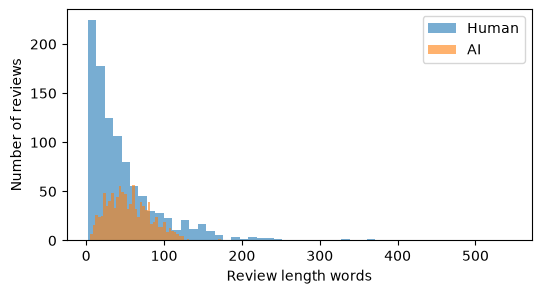

In [20]:
fig, ax = plt.subplots(figsize = (6,3))
for label, name in [(0, 'Human'), (1, 'AI')]:
    ax.hist(english_df.loc[english_df['source'] == label, 'n_words'], bins = 50, alpha = 0.6, label = name)
ax.set_xlabel('Review length words')
ax.set_ylabel('Number of reviews')
ax.legend()
plt.savefig("Review_length.pdf", bbox_inches = 'tight')

1500
<class 'pandas.DataFrame'>
1 4769
2 2656
3 1987
4 1622
5 1345
6 1200
7 1077
8 984
9 914
10 836


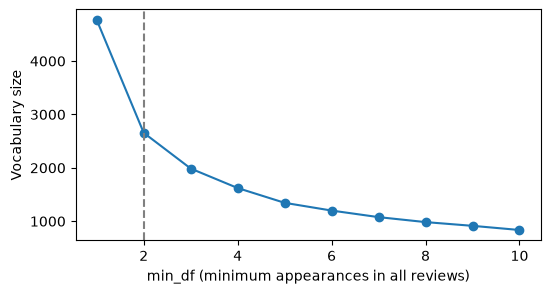

In [21]:
# load X_train for vocab vs min_df
X_train = pd.read_csv('data/X_train.csv')
X_train_cr = X_train['Combined_Review']

print(len(X_train))
print(type(X_train))


thresholds = [i for i in range(1,11)]
vocaubalry_size = []
for threshold in thresholds:
    vec = CountVectorizer(min_df= threshold, max_df = 0.95)
    vec.fit(X_train_cr)
    vocaubalry_size.append(len(vec.vocabulary_))

# plot graphs per threshold

for threshold, vocab in zip(thresholds, vocaubalry_size):
    print(threshold, vocab)


fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(thresholds, vocaubalry_size, marker="o")
ax.axvline(2, linestyle="--", color="grey")  
ax.set_xlabel("min_df (minimum appearances in all reviews)")
ax.set_ylabel("Vocabulary size")
plt.savefig("vocab_vs_mindf.pdf", bbox_inches="tight")